In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("../data/COVID-19_Radiography_Dataset")
covid = pd.read_excel(DATA / "COVID.metadata.xlsx")
covid.head()

,FILE NAME,FORMAT,SIZE,URL
0,COVID-1,PNG,256*256,https://sirm.org/category/senza-categoria/covi...
1,COVID-2,PNG,256*256,https://sirm.org/category/senza-categoria/covi...
2,COVID-3,PNG,256*256,https://sirm.org/category/senza-categoria/covi...
3,COVID-4,PNG,256*256,https://sirm.org/category/senza-categoria/covi...
4,COVID-5,PNG,256*256,https://sirm.org/category/senza-categoria/covi...


In [2]:
files = {
    "COVID": "COVID.metadata.xlsx",
    "Lung_Opacity": "Lung_Opacity.metadata.xlsx",
    "Normal": "Normal.metadata.xlsx",
    "Viral Pneumonia": "Viral Pneumonia.metadata.xlsx",
}

meta = {}
for klasse, datei in files.items():
    meta[klasse] = pd.read_excel(DATA / datei)
    print(klasse, meta[klasse].shape)
    print(list(meta[klasse].columns))
    print()

COVID (3616, 4)
['FILE NAME', 'FORMAT', 'SIZE', 'URL']

Lung_Opacity (6012, 4)
['FILE NAME', 'FORMAT', 'SIZE', 'URL']

Normal (10192, 4)
['FILE NAME', 'FORMAT', 'SIZE', 'URL']

Viral Pneumonia (1345, 4)
['FILE NAME', 'FORMAT', 'SIZE', 'URL']



In [3]:
for klasse, df in meta.items():
    print(klasse)
    print("Fehlende Werte:")
    print(df.isna().sum())
    print("Doppelte Zeilen:", df.duplicated().sum())
    print("Doppelte Dateinamen:", df["FILE NAME"].duplicated().sum())
    print(df["FORMAT"].value_counts())
    print(df["SIZE"].value_counts())
    print()

COVID
Fehlende Werte:
FILE NAME    0
FORMAT       0
SIZE         0
URL          0
dtype: int64
Doppelte Zeilen: 0
Doppelte Dateinamen: 0
FORMAT
PNG    3616
Name: count, dtype: int64
SIZE
256*256    3616
Name: count, dtype: int64

Lung_Opacity
Fehlende Werte:
FILE NAME    0
FORMAT       0
SIZE         0
URL          0
dtype: int64
Doppelte Zeilen: 0
Doppelte Dateinamen: 0
FORMAT
PNG    6012
Name: count, dtype: int64
SIZE
256*256    6012
Name: count, dtype: int64

Normal
Fehlende Werte:
FILE NAME    0
FORMAT       0
SIZE         0
URL          0
dtype: int64
Doppelte Zeilen: 0
Doppelte Dateinamen: 0
FORMAT
PNG    10192
Name: count, dtype: int64
SIZE
256*256    10192
Name: count, dtype: int64

Viral Pneumonia
Fehlende Werte:
FILE NAME    0
FORMAT       0
SIZE         0
URL          0
dtype: int64
Doppelte Zeilen: 0
Doppelte Dateinamen: 0
FORMAT
PNG    1345
Name: count, dtype: int64
SIZE
256*256    1345
Name: count, dtype: int64



In [4]:
from PIL import Image

for klasse in files:
    bild = next((DATA / klasse).rglob("*.png"))
    print(klasse, "|", bild.relative_to(DATA), "|", Image.open(bild).size)

COVID | COVID\images\COVID-1.png | (299, 299)
Lung_Opacity | Lung_Opacity\images\Lung_Opacity-1.png | (299, 299)
Normal | Normal\images\Normal-1.png | (299, 299)
Viral Pneumonia | Viral Pneumonia\images\Viral Pneumonia-1.png | (299, 299)


In [5]:
for klasse, df in meta.items():
    ordner = DATA / klasse / "images"
    dateien = {p.stem for p in ordner.glob("*.png")}
    namen = set(df["FILE NAME"])
    print(
        klasse,
        "| Dateien:", len(dateien),
        "| Metadaten:", len(namen),
        "| nur in Metadaten:", len(namen - dateien),
        "| nur im Ordner:", len(dateien - namen),
    )

COVID | Dateien: 3616 | Metadaten: 3616 | nur in Metadaten: 0 | nur im Ordner: 0
Lung_Opacity | Dateien: 6012 | Metadaten: 6012 | nur in Metadaten: 0 | nur im Ordner: 0
Normal | Dateien: 10192 | Metadaten: 10192 | nur in Metadaten: 10192 | nur im Ordner: 10192
Viral Pneumonia | Dateien: 1345 | Metadaten: 1345 | nur in Metadaten: 0 | nur im Ordner: 0


In [6]:
rows = {}
for klasse, df in meta.items():
    rows[klasse] = {
        "Zeilen": len(df),
        "Fehlende Werte": int(df.isna().sum().sum()),
        "Doppelte Zeilen": int(df.duplicated().sum()),
        "Doppelte Dateinamen": int(df["FILE NAME"].duplicated().sum()),
        "Anzahl Formate": df["FORMAT"].nunique(),
        "Anzahl Größen": df["SIZE"].nunique(),
        "Anzahl URLs": df["URL"].nunique(),
    }

summary = pd.DataFrame.from_dict(rows, orient="index")
summary

,Zeilen,Fehlende Werte,Doppelte Zeilen,Doppelte Dateinamen,Anzahl Formate,Anzahl Größen,Anzahl URLs
COVID,3616,0,0,0,1,1,6
Lung_Opacity,6012,0,0,0,1,1,1
Normal,10192,0,0,0,1,1,2
Viral Pneumonia,1345,0,0,0,1,1,1


In [8]:
for klasse in ["COVID", "Normal"]:
    print(klasse)
    print(meta[klasse]["URL"].value_counts())
    print()

COVID
URL
https://bimcv.cipf.es/bimcv-projects/bimcv-covid19/#1590858128006-9e640421-6711    2474
https://github.com/armiro/COVID-CXNet                                               400
https://eurorad.org                                                                 258
https://github.com/ml-workgroup/covid-19-image-repository/tree/master/png           183
https://github.com/ieee8023/covid-chestxray-dataset                                 182
https://sirm.org/category/senza-categoria/covid-19/                                 119
Name: count, dtype: int64

Normal
URL
https://www.kaggle.com/c/rsna-pneumonia-detection-challenge/data    8851
https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia       1341
Name: count, dtype: int64



Klasse        COVID  Lung_Opacity  Normal  Viral Pneumonia
Quelle                                                    
COVID-CXNet     400             0       0                0
Eurorad         258             0       0                0
ML-Workgroup    183             0       0                0
PadChest       2474             0       0                0
Pneumonia-DB      0             0    1341             1345
RSNA              0          6012    8851                0
SIRM            119             0       0                0
ieee8023        182             0       0                0

Anzahl Klassen pro Quelle:
Quelle
COVID-CXNet     1
Eurorad         1
ML-Workgroup    1
PadChest        1
Pneumonia-DB    2
RSNA            2
SIRM            1
ieee8023        1
dtype: int64


<Axes: xlabel='Quelle'>

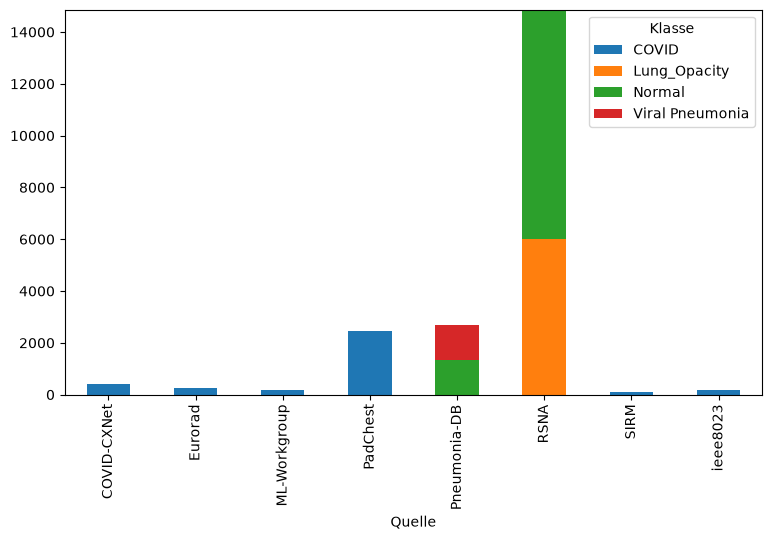

In [9]:
teile = []
for klasse, df in meta.items():
    df = df.copy()
    df["Klasse"] = klasse
    teile.append(df)
alle = pd.concat(teile, ignore_index=True)

namen = {
    "bimcv": "PadChest",
    "COVID-CXNet": "COVID-CXNet",
    "eurorad": "Eurorad",
    "ml-workgroup": "ML-Workgroup",
    "ieee8023": "ieee8023",
    "sirm": "SIRM",
    "rsna": "RSNA",
    "chest-xray-pneumonia": "Pneumonia-DB",
}
for schluessel, kurzname in namen.items():
    alle.loc[alle["URL"].str.contains(schluessel), "Quelle"] = kurzname

tab = pd.crosstab(alle["Quelle"], alle["Klasse"])
print(tab)
print()
print("Anzahl Klassen pro Quelle:")
print((tab > 0).sum(axis=1))

tab.plot(kind="bar", stacked=True, figsize=(9, 5))

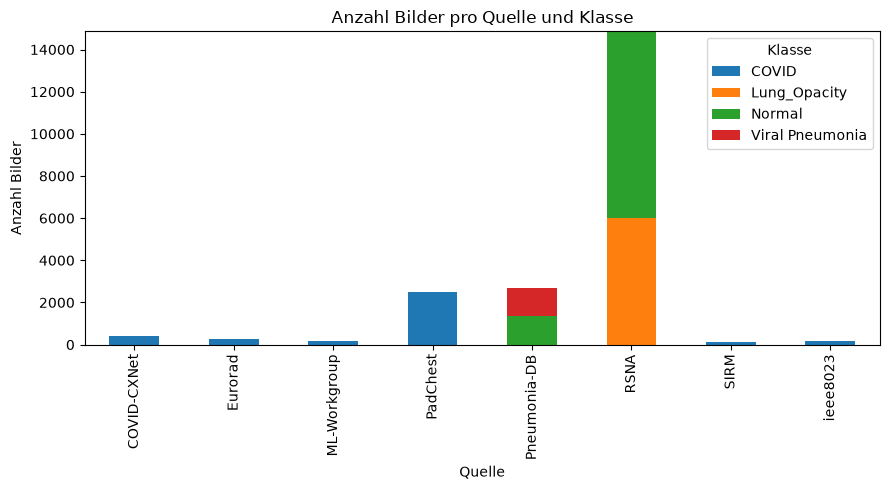

In [11]:
import matplotlib.pyplot as plt

tab.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Anzahl Bilder pro Quelle und Klasse")
plt.xlabel("Quelle")
plt.ylabel("Anzahl Bilder")
plt.tight_layout()
plt.show()

                 Anzahl  Anteil %
Klasse                           
Normal            10192      48.2
Lung_Opacity       6012      28.4
COVID              3616      17.1
Viral Pneumonia    1345       6.4


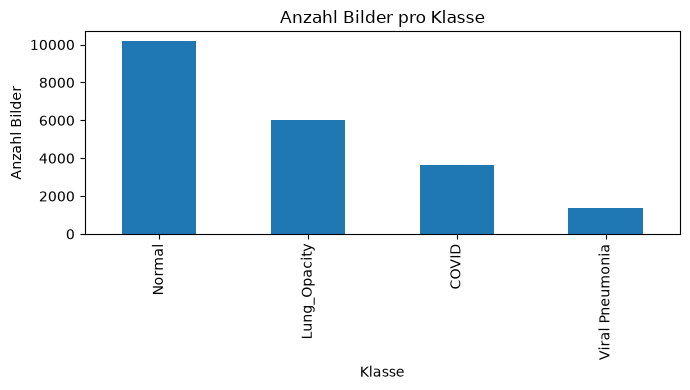

In [21]:
import matplotlib.pyplot as plt
from scipy.stats import chisquare, kruskal, mannwhitneyu

anzahl = alle["Klasse"].value_counts()
anteil = (anzahl / anzahl.sum() * 100).round(1)
print(pd.DataFrame({"Anzahl": anzahl, "Anteil %": anteil}))

fig, ax = plt.subplots(figsize=(7, 4))
anzahl.plot(kind="bar", ax=ax)
ax.set_title("Anzahl Bilder pro Klasse")
ax.set_xlabel("Klasse")
ax.set_ylabel("Anzahl Bilder")
fig.tight_layout()
plt.show()


In [15]:
import cv2
import numpy as np

N = 500
rng = np.random.default_rng(42)

zeilen = []
for klasse in files:
    pfade = sorted((DATA / klasse / "images").glob("*.png"))
    auswahl = rng.choice(len(pfade), size=N, replace=False)
    for i in auswahl:
        bild = cv2.imread(str(pfade[i]), cv2.IMREAD_GRAYSCALE)
        zeilen.append({
            "Klasse": klasse,
            "Datei": pfade[i].stem,
            "Helligkeit": bild.mean(),
            "Kontrast": bild.std(),
        })

helligkeit = pd.DataFrame(zeilen)
helligkeit.groupby("Klasse")[["Helligkeit", "Kontrast"]].mean().round(1)

,Helligkeit,Kontrast
Klasse,,
COVID,139.9,54.1
Lung_Opacity,124.4,57.3
Normal,127.1,62.1
Viral Pneumonia,125.5,58.9


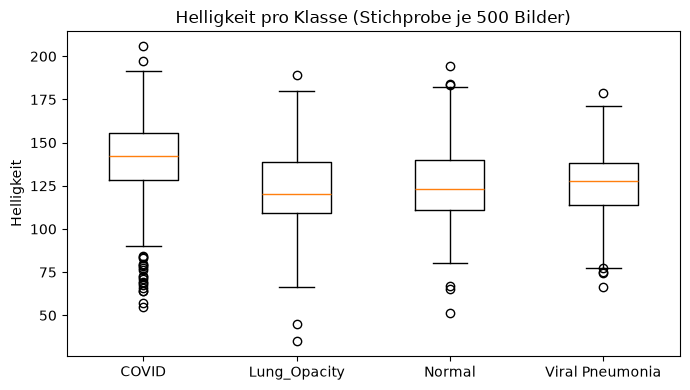

Klasse
COVID              142.4
Lung_Opacity       120.1
Normal             123.2
Viral Pneumonia    127.6
Name: Helligkeit, dtype: float64
Kruskal-Wallis H: 174.3 | p-Wert: 1.5079768251939806e-37


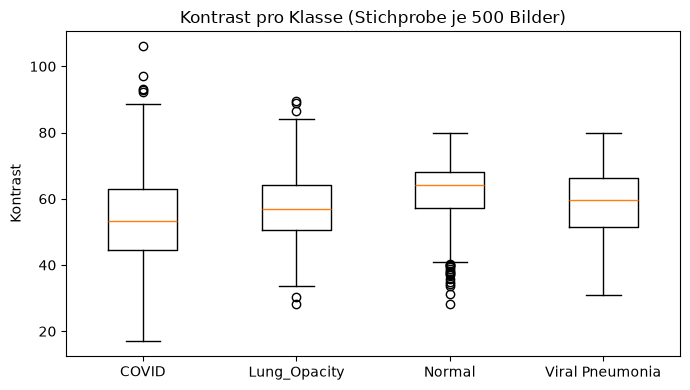

Klasse
COVID              53.4
Lung_Opacity       57.0
Normal             64.0
Viral Pneumonia    59.5
Name: Kontrast, dtype: float64
Kruskal-Wallis H: 139.2 | p-Wert: 5.75762341814999e-30


In [16]:
def vergleich_pro_klasse(spalte):
    klassen = list(files)
    gruppen = [helligkeit.loc[helligkeit["Klasse"] == k, spalte] for k in klassen]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.boxplot(gruppen, tick_labels=klassen)
    ax.set_title(f"{spalte} pro Klasse (Stichprobe je {N} Bilder)")
    ax.set_ylabel(spalte)
    fig.tight_layout()
    plt.show()

    print(helligkeit.groupby("Klasse")[spalte].median().round(1))
    h, p = kruskal(*gruppen)
    print("Kruskal-Wallis H:", round(h, 1), "| p-Wert:", p)

vergleich_pro_klasse("Helligkeit")
vergleich_pro_klasse("Kontrast")

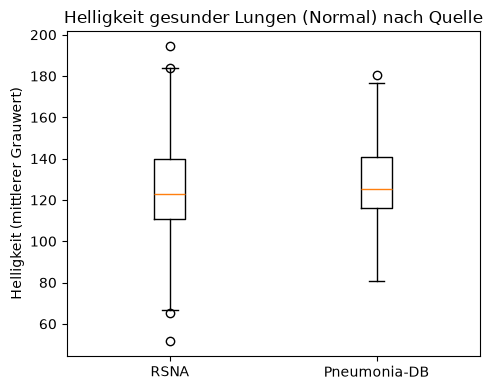

Bilder RSNA: 440 | Pneumonia-DB: 60
Median RSNA: 122.9 | Median Pneumonia-DB: 125.5
Mann-Whitney U: 11988.0 | p-Wert: 0.2485138884246425


In [17]:
alle["key"] = alle["FILE NAME"].str.lower()
helligkeit["key"] = helligkeit["Datei"].str.lower()
m = helligkeit.merge(alle[["key", "Quelle"]], on="key")

normal = m[m["Klasse"] == "Normal"]
rsna = normal.loc[normal["Quelle"] == "RSNA", "Helligkeit"]
pneu = normal.loc[normal["Quelle"] == "Pneumonia-DB", "Helligkeit"]

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([rsna, pneu], tick_labels=["RSNA", "Pneumonia-DB"])
ax.set_title("Helligkeit gesunder Lungen (Normal) nach Quelle")
ax.set_ylabel("Helligkeit (mittlerer Grauwert)")
fig.tight_layout()
plt.show()

print("Bilder RSNA:", len(rsna), "| Pneumonia-DB:", len(pneu))
print("Median RSNA:", round(rsna.median(), 1), "| Median Pneumonia-DB:", round(pneu.median(), 1))
u, p = mannwhitneyu(rsna, pneu)
print("Mann-Whitney U:", u, "| p-Wert:", p)

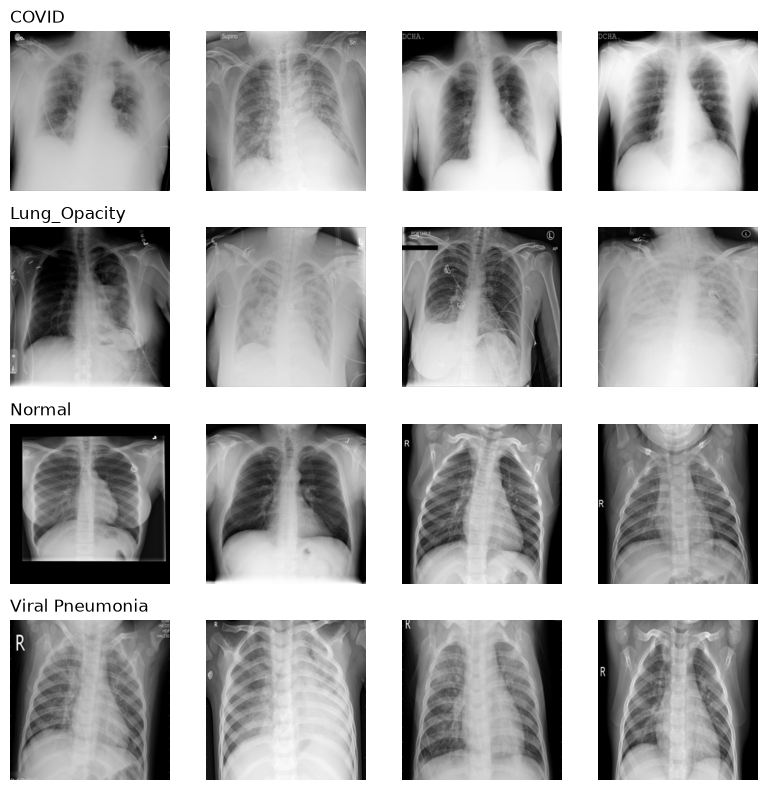

In [20]:
fig, axes = plt.subplots(len(files), 4, figsize=(8, 8))
for zeile, klasse in enumerate(files):
    pfade = sorted((DATA / klasse / "images").glob("*.png"))[:4]
    for spalte, pfad in enumerate(pfade):
        axes[zeile, spalte].imshow(cv2.imread(str(pfad), cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[zeile, spalte].axis("off")
    axes[zeile, 0].set_title(klasse, loc="left")
fig.tight_layout()
plt.show()